In [1]:
#load the two datasets
from pathlib import Path
import pandas as pd

data_dir = Path.cwd() / 'data'
file_path_obama = data_dir / 'Obama_Speeches.csv'
file_path_trump = data_dir / 'Trump_Labeled_Combined_Rev_Speeches_Final_9-24-2024.csv'

full_obama = pd.read_csv(file_path_obama)
full_trump = pd.read_csv(file_path_trump)

#sort original dataset by date
full_trump['date'] = pd.to_datetime(full_trump['date'])
full_trump = (full_trump.sort_values('date').reset_index(drop=True))

full_obama['date'] = pd.to_datetime(full_obama['date'])
full_obama = (full_obama.sort_values('date').reset_index(drop=True))



obama = pd.concat([full_obama.iloc[:50], full_obama.iloc[-50:]]).reset_index(drop=True) #removing outliers
trump = pd.concat([full_trump.iloc[7:57], full_trump.iloc[-50:]]).reset_index(drop=True)

#(sub 1.2 working with data)

In [2]:
#extract the relevant columns/data and change the order of the columns
trump = trump[['date', 'title','transcript', 'word_count', 'stop_word_count', 'non_stopwords']].copy()
#change order of columns
obama = obama[['date', 'title', 'transcript']]

#(sub 1.3 working with data)

In [ ]:
#add 'word_count', 'stop_word_count', 'non_stopwords' to the obama dataset
from gensim.utils import simple_preprocess
from nltk.corpus import stopwords

#tokenize, lowercase, removes punctuation, count the words
obama['word_count'] = [
    len(simple_preprocess(speech, min_len=1, max_len=100))
    for speech in obama['transcript']]

#count the stopwords
stop_words = stopwords.words('english')
obama['stop_word_count'] = [
    len([word for word in simple_preprocess(speech, min_len=1, max_len=100)
         if word in stop_words])
    for speech in obama['transcript']]

#extract non_stopwords
obama['non_stopwords'] = [
    ' '.join([word for word in simple_preprocess(speech)
              if word not in stop_words])
    for speech in obama['transcript']]

#calculate stopwords as a percentage of all words
obama['stop_word_rate'] = (obama['stop_word_count'] / obama['word_count'] * 100)

#add back stop_word_rate for Trump, our own calculation
trump['stop_word_rate'] = (trump['stop_word_count'] / trump['word_count'] * 100)


print(len(trump))
display(trump[-50:])

display(len(obama))
display(obama[-50:])

#(workshop nlp, nlp_canvas.ipynb)

100


,date,title,transcript,word_count,stop_word_count,non_stopwords,stop_word_rate
50,2023-12-20,trump-holds-rally-in-iowa-moments-after-colora...,"waterloo, thank you very much. it’s great to b...",10481,5375,waterloo thank much great lot people outside l...,51.283274
51,2024-01-08,donald-trump-election-campaign-rally-in-sioux-...,thank you very much. we’re going to take our c...,19121,9874,thank much going take country back going take ...,51.639559
52,2024-01-10,trump-speaks-after-court-hearing-on-whether-he...,"well, i want to thank you all, and we had a ve...",1221,668,well want thank momentous day terms learned th...,54.709255
53,2024-01-11,iowa-town-hall-with-donald-trump-1-10-24-trans...,"thank you very much. all right, bret. thank yo...",6251,3288,thank much right bret thank much thank much go...,52.599584
54,2024-01-22,donald-trump-holds-campaign-event-in-rochester...,"thank you. thank you. wow, what a crowd. you g...",13018,6685,thank thank wow crowd got lot people standing ...,51.351974
55,2024-01-24,trump-speaks-after-winning-new-hampshire-prima...,"thank you everybody. thank you. whoa. well, i ...",2441,1325,thank everybody thank whoa well want thank eve...,54.281032
56,2024-01-29,donald-trump-speaks-at-rally-in-las-vegas-tran...,thank you very much. thank you. thank you. tha...,12420,6113,thank much thank thank thank much thank know o...,49.219002
57,2024-02-01,trump-holds-news-conference-after-meeting-with...,"well, thank you very much. we had a very stron...",3100,1692,well thank much strong meeting teamsters years...,54.580645
58,2024-02-12,donald-trump-delivers-speech-in-south-carolina...,"well, thank you very much, south carolina. we’...",15133,7594,well thank much south carolina weve great rela...,50.181722
59,2024-02-18,trump-speaks-after-new-york-civil-fraud-ruling...,"well, thank you very much. it’s a very sad day...",993,512,well thank much sad day opinion country new yo...,51.560926


100

,date,title,transcript,word_count,stop_word_count,non_stopwords,stop_word_rate
50,2015-11-12,Remarks by the President in Medal of Honor Pre...,"Good morning, and welcome to the White House. ...",1829,919,good morning welcome white house little three ...,50.246036
51,2015-11-13,Remarks by the President in Meeting on the Tra...,"As many of you know, this weekend I will be le...",870,489,many know weekend leaving trip taking annual t...,56.206897
52,2015-11-14,Weekly Address: Giving Veterans their Chance,"Hi, everybody. This week, America came togethe...",523,260,hi everybody week america came together salute...,49.713193
53,2015-11-15,Remarks by President Obama and President Tayyi...,"Well, let me begin by thanking President Erdog...",454,243,well let begin thanking president erdogan peop...,53.524229
54,2015-11-17,Remarks by President Obama After Touring the B...,"Good afternoon, everybody. It is wonderful to ...",287,138,good afternoon everybody wonderful back philip...,48.083624
55,2015-11-17,Remarks by President Obama and Prime Minister ...,"Well, it is a wonderful opportunity for me to ...",508,285,well wonderful opportunity lengthy discussion ...,56.102362
56,2015-11-18,Remarks by the President at CEO Summit,Thank you! (Applause.) Thank you so much. Than...,1903,989,thank applause thank much thank everybody plea...,51.970573
57,2015-11-18,Remarks by the President at CEO Summit,"PRESIDENT OBAMA: Now, you mentioned the need f...",1257,687,president obama mentioned need continuous inno...,54.653938
58,2015-11-18,Remarks by President Obama in Meeting on the T...,"Well, I want to welcome all the leaders and tr...",411,216,well want welcome leaders trade ministers mark...,52.554745
59,2015-11-19,Remarks by President Obama and Prime Minister ...,"Well, it is good once again to be with my frie...",406,206,well good friend prime minister abe japanese d...,50.738916


## Visualisering

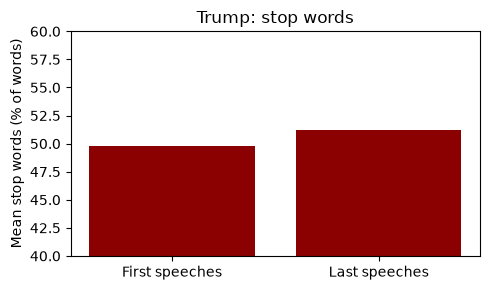

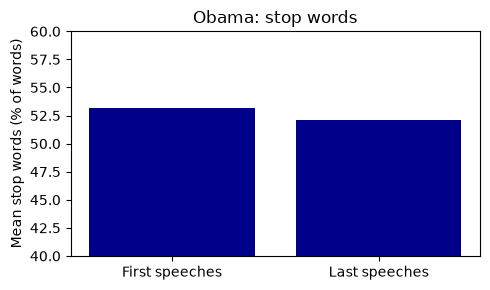

In [12]:
#visualize and compare speeches
import matplotlib.pyplot as plt

#trumps first vs last speeches
trump_rates = [trump['stop_word_rate'].iloc[:50].mean(),
               trump['stop_word_rate'].iloc[-50:].mean()]

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(['First speeches', 'Last speeches'],
       trump_rates,
       color=['darkred'])
ax.set_title('Trump: stop words')
ax.set_ylabel('Mean stop words (% of words)')
ax.set_ylim(40,60)
plt.tight_layout()
plt.show()

#obama first vs last speeches
obama_rates = [obama['stop_word_rate'].iloc[:50].mean(),
               obama['stop_word_rate'].iloc[-50:].mean()]

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(['First speeches', 'Last speeches'],
       obama_rates,
       color=['darkblue'])
ax.set_title('Obama: stop words')
ax.set_ylabel('Mean stop words (% of words)')
ax.set_ylim(40,60)
plt.tight_layout()
plt.show()

#(sub 1.4 visualisations)

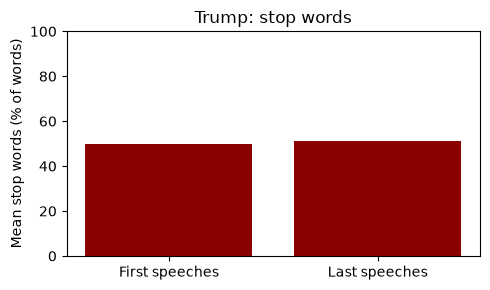

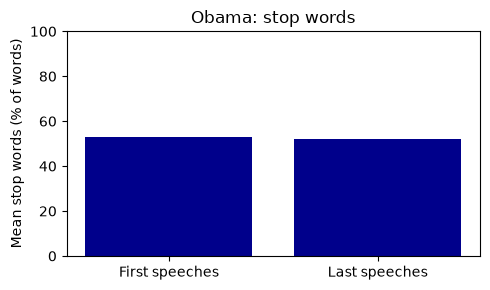

In [13]:
#visualize and compare speeches
import matplotlib.pyplot as plt

#trumps first five vs last five speeches
trump_rates = [trump['stop_word_rate'].iloc[:50].mean(),
               trump['stop_word_rate'].iloc[-50:].mean()]

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(['First speeches', 'Last speeches'],
       trump_rates,
       color=['darkred'])
ax.set_title('Trump: stop words')
ax.set_ylabel('Mean stop words (% of words)')
ax.set_ylim(0,100)
plt.tight_layout()
plt.show()

#obama first five vs last five speeches
obama_rates = [obama['stop_word_rate'].iloc[:50].mean(),
               obama['stop_word_rate'].iloc[-50:].mean()]

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(['First speeches', 'Last speeches'],
       obama_rates,
       color=['darkblue'])
ax.set_title('Obama: stop words')
ax.set_ylabel('Mean stop words (% of words)')
ax.set_ylim(0,100)
plt.tight_layout()
plt.show()

#(sub 1.4 visualisations)

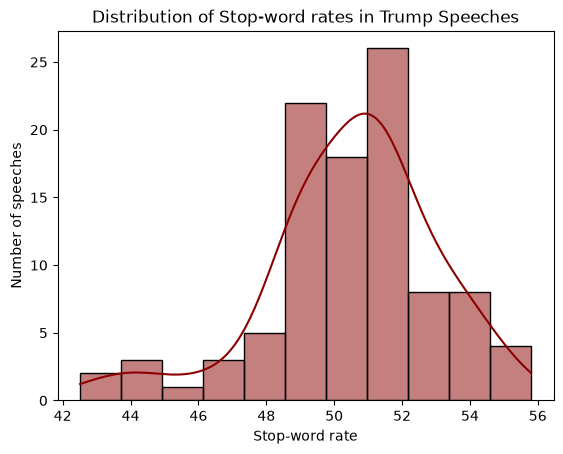

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(
    data=trump,
    x='stop_word_rate',
    color = 'darkred',
    kde=True
)

plt.xlabel('Stop-word rate')
plt.ylabel('Number of speeches')
plt.title('Distribution of Stop-word rates in Trump Speeches')
plt.show()

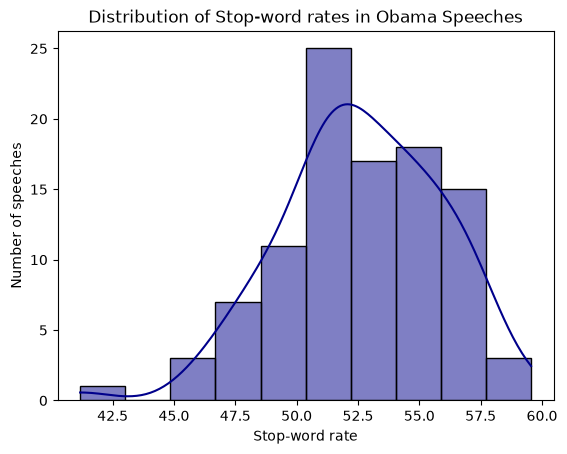

In [16]:
sns.histplot(
    data=obama,
    x='stop_word_rate',
    color = 'darkblue',
    kde=True
)

plt.xlabel('Stop-word rate')
plt.ylabel('Number of speeches')
plt.title('Distribution of Stop-word rates in Obama Speeches')
plt.show()

<Axes: xlabel='date', ylabel='stop_word_rate'>

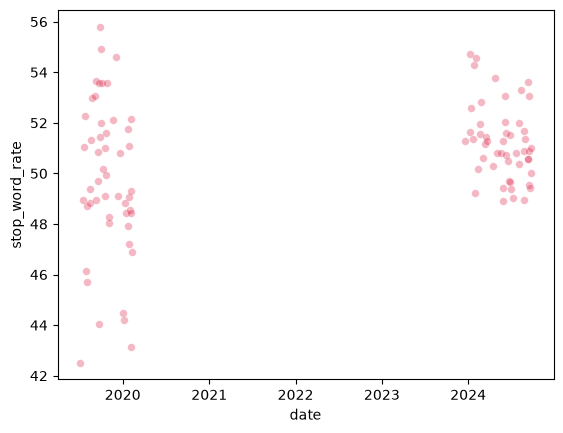

In [17]:
sns.scatterplot(data=trump, x='date', y='stop_word_rate',
                color= 'crimson', s=30, alpha=0.3)

<Axes: xlabel='date', ylabel='stop_word_rate'>

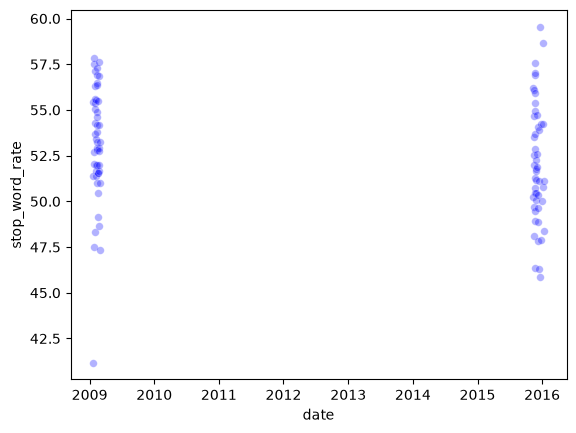

In [18]:
sns.scatterplot(data=obama, x='date', y='stop_word_rate',
                color= 'blue', s=30, alpha=0.3)